# IR Project — Phase 1: arXiv cs.CL Hybrid Search
**Sub-topics:** Question Answering · Machine Translation · Text Summarization · Dialogue Systems

Steps: (1) load the corpus collected by `collect_corpus.ipynb` → (2) corpus statistics report → (3) BM25 + dense indexes → (4) query handling → (5) RRF fusion + rerank → (6) GUI.

Put this notebook in the repo folder next to `Data/` and run **Kernel → Restart & Run All**.

In [1]:
%pip install -q rank_bm25 sentence-transformers symspellpy gradio pandas matplotlib nltk scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 0. Settings

In [2]:
import re, json, html
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
from tqdm.auto import tqdm

DATA = Path("Data")                      # the folder from our GitHub repo
CORPUS_JSON = DATA / "corpus.json"       # metadata of all papers (made by collect_corpus.ipynb)
TEXT_DIR = DATA / "texts"                # full text of each paper, one .txt per paper

## 1. Load the corpus
The corpus was collected by `collect_corpus.ipynb` and saved in `Data/`:
`corpus.json` holds each paper's metadata (title, arXiv ID, link, sub-topic, pages, length tier) and `Data/texts/<arxiv_id>.txt` holds its full text.
This cell joins the two into one list, `corpus`, that the rest of the notebook uses, and checks the Phase 1 corpus requirements.

In [3]:
raw = json.load(open(CORPUS_JSON, encoding="utf-8"))

corpus = []
for p in raw:
    text_path = TEXT_DIR / Path(p["text_file"]).name
    text = text_path.read_text(encoding="utf-8", errors="ignore") if text_path.exists() else ""
    corpus.append({
        "arxiv_id": p["arxiv_id"],
        "title": p["title"],
        "abstract": p["abstract"],
        "published": p.get("published", ""),
        "primary_category": p.get("primary_category", ""),
        "subtopic": p["subtopic"],
        "pages": p["pages"],
        "length_tier": str(p["length_category"]).lower(),
        "arxiv_url": p["url"],
        "text": " ".join(text.split()),
    })

df = pd.DataFrame(corpus)
N = len(corpus)

missing = (df.text.str.len() == 0).sum()
print(f"{N} papers loaded, {missing} with missing text files")
print("OK  >= 400 papers" if N >= 400 else "NOT OK  fewer than 400 papers")
print("OK  >= 4 sub-topics" if df.subtopic.nunique() >= 4 else "NOT OK  fewer than 4 sub-topics")
print("OK  all 3 length tiers" if {"short", "medium", "long"} <= set(df.length_tier) else "NOT OK  a length tier is missing")
pd.crosstab(df.subtopic, df.length_tier, margins=True)

400 papers loaded, 0 with missing text files
OK  >= 400 papers
OK  >= 4 sub-topics
OK  all 3 length tiers


length_tier,long,medium,short,All
subtopic,,,,
dialogue systems,73,16,11,100
machine translation,79,19,2,100
question answering,78,18,4,100
text summarization,69,22,9,100
All,299,75,26,400


## 2. Corpus statistics report (PDF deliverable)

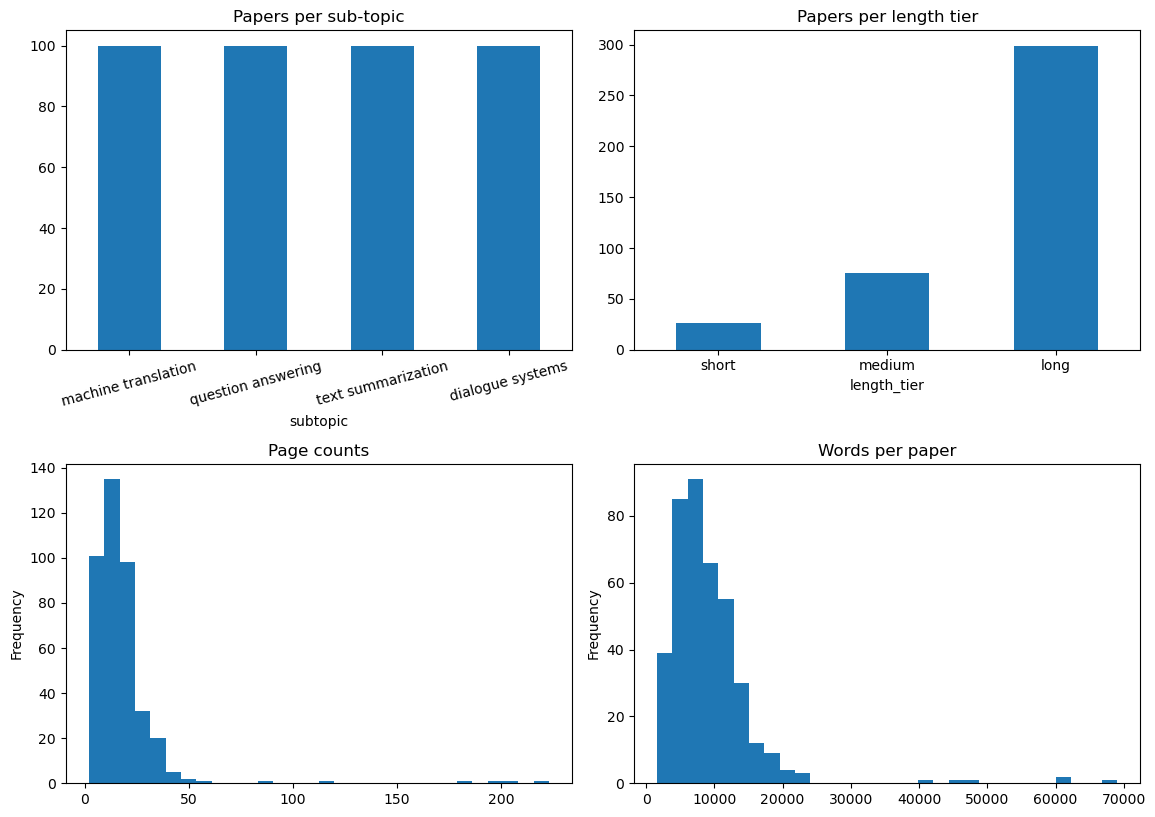

Saved corpus_statistics_report.pdf


In [4]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

df["words"] = df.text.str.split().str.len()
table = pd.crosstab(df.subtopic, df.length_tier, margins=True)
stats = df.groupby("subtopic").agg(papers=("arxiv_id", "count"), avg_pages=("pages", "mean"),
                                   avg_words=("words", "mean")).round(1)
log = json.load(open(DATA / "collection_log.json", encoding="utf-8"))

with PdfPages("corpus_statistics_report.pdf") as pdf:
    # page 1: text
    fig = plt.figure(figsize=(8.27, 11.69))
    lines = ["Phase 1 - Corpus Statistics (arXiv cs.CL)", "",
             "Team: <names / IDs>",
             f"Total papers: {N}   |   sub-topics: {df.subtopic.nunique()}   |   "
             f"published {df.published.min()} to {df.published.max()}",
             "", "How the corpus was collected (Data/collection_log.json):"]
    for line in json.dumps(log, indent=1, ensure_ascii=False).splitlines()[:25]:
        lines += [line[i:i + 100] for i in range(0, max(len(line), 1), 100)]
    lines += ["", "Papers per sub-topic and length tier:", *table.to_string().splitlines(),
              "", "Averages per sub-topic:", *stats.to_string().splitlines(),
              "", "Length tiers by page count of the arXiv PDF: short, medium, long."]
    for start in range(0, len(lines), 52):                      # 52 lines per page
        if start: fig = plt.figure(figsize=(8.27, 11.69))
        for i, line in enumerate(lines[start:start + 52]):
            fig.text(0.06, 0.95 - i * 0.018, line, family="monospace", fontsize=8.5,
                     weight="bold" if start == 0 and i == 0 else "normal")
        pdf.savefig(fig); plt.close(fig)

    # page 2: charts
    fig, ax = plt.subplots(2, 2, figsize=(11.69, 8.27))
    df.subtopic.value_counts().plot.bar(ax=ax[0, 0], rot=15, title="Papers per sub-topic")
    df.length_tier.value_counts().reindex(["short", "medium", "long"]).fillna(0).plot.bar(ax=ax[0, 1], rot=0, title="Papers per length tier")
    df.pages.plot.hist(bins=30, ax=ax[1, 0], title="Page counts")
    df.words.plot.hist(bins=30, ax=ax[1, 1], title="Words per paper")
    fig.tight_layout(); pdf.savefig(fig); plt.show()

print("Saved corpus_statistics_report.pdf")

## 3. Indexes
**BM25:** text is lower-cased (→ case-insensitive), stop words removed, Porter-stemmed. Indexed field = title + abstract + full text.
**Dense:** each paper's title + abstract is embedded with `all-MiniLM-L6-v2`; similarity = cosine.

In [5]:
from rank_bm25 import BM25Okapi
from nltk.stem import PorterStemmer
from sentence_transformers import SentenceTransformer, CrossEncoder
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stemmer = PorterStemmer()

def tokenize(text):
    words = re.findall(r"[a-z0-9]+", text.lower())
    return [stemmer.stem(w) for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 1]

bm25 = BM25Okapi([tokenize(d["title"] + " " + d["abstract"] + " " + d["text"]) for d in tqdm(corpus)])

dense_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
doc_emb = dense_model.encode([d["title"] + ". " + d["abstract"] for d in corpus],
                             normalize_embeddings=True, show_progress_bar=True)
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")
print("indexes ready")

W1102 19:05:34.450000 9839 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


  0%|          | 0/400 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (3 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

indexes ready


## 4. Query handling
- **Case-insensitive:** query lower-cased.
- **Spelling correction:** SymSpell, dictionary = words of our own corpus, so NLP terms are known.
- **Abbreviation expansion:** e.g. `nmt` → adds "neural machine translation" (the acronym is kept too).
- **Phrase matching:** text in `"quotes"` must appear exactly in the paper.

In [6]:
from symspellpy import SymSpell, Verbosity

ABBREVIATIONS = {
    "nlp": "natural language processing", "mt": "machine translation", "nmt": "neural machine translation",
    "qa": "question answering", "odqa": "open domain question answering", "llm": "large language model",
    "llms": "large language models", "ner": "named entity recognition", "rag": "retrieval augmented generation",
    "nli": "natural language inference", "dst": "dialogue state tracking", "tod": "task oriented dialogue",
    "mrc": "machine reading comprehension", "rl": "reinforcement learning", "asr": "automatic speech recognition",
}

spell = SymSpell(max_dictionary_edit_distance=2)
word_counts = Counter(w for d in corpus for w in re.findall(r"[a-z]+", (d["title"] + " " + d["abstract"] + " " + d["text"]).lower()))
for w, c in word_counts.items():
    if c >= 3 and len(w) >= 3:
        spell.create_dictionary_entry(w, c)

def process_query(query, use_spell=True, use_abbr=True):
    q = query.lower()
    corrections, expansions = {}, {}
    if use_spell:
        def fix(m):
            w = m.group(0)
            if len(w) < 3 or w in ABBREVIATIONS or w in spell.words:
                return w
            s = spell.lookup(w, Verbosity.CLOSEST, max_edit_distance=2)
            if s and s[0].term != w:
                corrections[w] = s[0].term
                return s[0].term
            return w
        q = re.sub(r"[a-z]+", fix, q)
    phrases = re.findall(r'"([^"]+)"', q)
    plain = q.replace('"', " ")
    if use_abbr:
        for w in re.findall(r"[a-z0-9]+", plain):
            if w in ABBREVIATIONS:
                expansions[w] = ABBREVIATIONS[w]
    full = plain + " " + " ".join(expansions.values())
    return {"text": " ".join(full.split()), "tokens": tokenize(full), "phrases": phrases,
            "corrections": corrections, "expansions": expansions}

process_query('NMT for low-resourse langauges "machine translation"')

{'text': 'nmt for low-resource languages machine translation neural machine translation',
 'tokens': ['nmt',
  'low',
  'resourc',
  'languag',
  'machin',
  'translat',
  'neural',
  'machin',
  'translat'],
 'phrases': ['machine translation'],
 'corrections': {'resourse': 'resource', 'langauges': 'languages'},
 'expansions': {'nmt': 'neural machine translation'}}

## 5. Retrieval: BM25, Dense, RRF fusion, RRF + rerank
**RRF:** `score(d) = 1/(60 + rank_BM25(d)) + 1/(60 + rank_dense(d))`. It uses ranks, not raw scores, so the different score scales of BM25 and cosine don't matter.
**Rerank:** the RRF top-30 is re-scored by a cross-encoder, which reads query and paper together (more accurate, but too slow for the whole corpus).

In [7]:
def phrase_ok(doc, phrases):
    text = (doc["title"] + " " + doc["abstract"] + " " + doc["text"]).lower()
    return all(p in text for p in phrases)

def search(query, method="RRF fusion", use_spell=True, use_abbr=True, k=10):
    q = process_query(query, use_spell, use_abbr)
    allowed = [i for i in range(N) if phrase_ok(corpus[i], q["phrases"])]

    bm25_scores = bm25.get_scores(q["tokens"])
    dense_scores = doc_emb @ dense_model.encode(q["text"], normalize_embeddings=True)
    bm25_rank  = sorted(allowed, key=lambda i: -bm25_scores[i])
    dense_rank = sorted(allowed, key=lambda i: -dense_scores[i])

    if method == "BM25":
        results = [(i, bm25_scores[i]) for i in bm25_rank[:k]]
    elif method == "Dense":
        results = [(i, dense_scores[i]) for i in dense_rank[:k]]
    else:
        rrf = Counter()
        for ranking in (bm25_rank[:100], dense_rank[:100]):
            for r, i in enumerate(ranking, start=1):
                rrf[i] += 1 / (60 + r)
        results = rrf.most_common(k if method == "RRF fusion" else 30)
        if method == "RRF + rerank":
            pool = [i for i, _ in results]
            ce = reranker.predict([(q["text"], corpus[i]["title"] + ". " + corpus[i]["abstract"]) for i in pool])
            results = sorted(zip(pool, ce), key=lambda x: -x[1])[:k]
    return results, q

for i, score in search("low resource neural machine translation")[0][:5]:
    print(round(float(score), 4), corpus[i]["title"])

0.0325 Low-Resource Neural Machine Translation Using Recurrent Neural Networks and Transfer Learning: A Case Study on English-to-Igbo
0.0315 An Efficient Approach for Machine Translation on Low-resource Languages: A Case Study in Vietnamese-Chinese
0.0305 TULUN: Transparent and Adaptable Low-resource Machine Translation
0.0305 Beyond Vanilla Fine-Tuning: Leveraging Multistage, Multilingual, and Domain-Specific Methods for Low-Resource Machine Translation
0.0299 CycleDistill: Bootstrapping Machine Translation using LLMs with Cyclical Distillation


## 6. GUI

In [8]:
import gradio as gr

def snippet(doc, q, size=200):
    text = doc["abstract"]
    stems = set(q["tokens"])
    words = text.split()
    start = next((j for j, w in enumerate(words) if tokenize(w) and tokenize(w)[0] in stems), 0)
    s = " ".join(words[max(0, start - 3):])[:size]
    return ("… " if start > 3 else "") + s + "…"

def highlight(text, q):
    stems = set(q["tokens"])
    return re.sub(r"[A-Za-z0-9]+",
                  lambda m: f"<mark>{m.group(0)}</mark>" if tokenize(m.group(0)) and tokenize(m.group(0))[0] in stems else m.group(0),
                  html.escape(text))

def run(query, method, use_spell, use_abbr):
    if not query.strip():
        return ""
    results, q = search(query, method, use_spell, use_abbr)
    info = f"<p><b>Query used:</b> {html.escape(q['text'])}"
    if q["corrections"]: info += f"<br><b>Spelling fixed:</b> {q['corrections']}"
    if q["expansions"]:  info += f"<br><b>Expanded:</b> {q['expansions']}"
    if q["phrases"]:     info += f"<br><b>Exact phrases:</b> {q['phrases']}"
    info += "</p>"
    rows = []
    for rank, (i, score) in enumerate(results, 1):
        d = corpus[i]
        rows.append(f"""<div style="margin:12px 0;padding:10px;border:1px solid #8884;border-radius:8px">
          <b>{rank}. <a href="{d['arxiv_url']}" target="_blank">{highlight(d['title'], q)}</a></b>
          <span style="float:right">score: {float(score):.4f}</span><br>
          <small>{d['arxiv_url']} · {d['subtopic']} · {d['pages']} pages ({d['length_tier']})</small><br>
          {highlight(snippet(d, q), q)}</div>""")
    return info + ("".join(rows) or "<p>No results.</p>")

with gr.Blocks(title="arXiv cs.CL Search") as demo:
    gr.Markdown(f"## arXiv cs.CL Hybrid Search ({N} papers)\nUse \"quotes\" for exact phrases.")
    query = gr.Textbox(label="Search")
    method = gr.Radio(["BM25", "Dense", "RRF fusion", "RRF + rerank"], value="RRF fusion", label="Model")
    with gr.Row():
        use_spell = gr.Checkbox(value=True, label="Spelling correction")
        use_abbr = gr.Checkbox(value=True, label="Abbreviation expansion")
    button = gr.Button("Search", variant="primary")
    output = gr.HTML()
    button.click(run, [query, method, use_spell, use_abbr], output)
    query.submit(run, [query, method, use_spell, use_abbr], output)

demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
